<a href="https://colab.research.google.com/github/SanikaKadam-2005/TNSCourse/blob/main/Cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# numpy helps us work with numbers and arrays
import numpy as np

# pandas lets us store data in a neat table, like a spreadsheet
import pandas as pd

# matplotlib is what we use to draw charts and pictures
import matplotlib.pyplot as plt

# make_blobs generates a simple practice dataset made of natural groups
from sklearn.datasets import make_blobs

# KMeans is the first clustering algorithm we're covering
from sklearn.cluster import KMeans

# AgglomerativeClustering is how scikit-learn runs Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering

# these two let us build and draw a dendrogram (the merge tree picture)
from scipy.cluster.hierarchy import linkage, dendrogram

# lock in the "randomness" so everyone gets the exact same numbers every time
np.random.seed(42)

# a simple message to confirm everything loaded properly
print("Ready to go!")
# the 3 rough "centers" our fake customer groups will be built around
group_centers = [[-4, -2], [0, 3], [4, -3]]

# make_blobs generates points scattered around each center, like real customers
# would naturally cluster around a few typical spending habits
raw_points, _ = make_blobs(n_samples=180, centers=group_centers, cluster_std=0.8, random_state=42)

# turn the first raw column into a realistic-looking dollar amount
# np.clip stops any value from going below $50 (nobody spends negative money)
annual_spend = np.clip(raw_points[:, 0] * 150 + 950, 50, None).round(0)

# turn the second raw column into a realistic-looking visit count
# np.clip stops any value from going below 1 visit per month
visits_per_month = np.clip(raw_points[:, 1] * 1.3 + 12, 1, None).round(1)

# put both features into one table
customers = pd.DataFrame({
    "annual_spend": annual_spend,
    "visits_per_month": visits_per_month
})

# show the first 10 rows so we can see what it looks like
customers.head(10)

Ready to go!


,annual_spend,visits_per_month
0,1432.0,8.6
1,977.0,17.3
2,831.0,15.3
3,1451.0,8.4
4,823.0,16.4
5,1520.0,6.8
6,375.0,7.4
7,862.0,16.1
8,1648.0,8.8
9,1584.0,7.5


   annual_spend  visits_per_month  cluster
0        1432.0               8.6        1
1         977.0              17.3        0
2         831.0              15.3        0
3        1451.0               8.4        1
4         823.0              16.4        0
5        1520.0               6.8        1
6         375.0               7.4        2
7         862.0              16.1        0
8        1648.0               8.8        1
9        1584.0               7.5        1

Cluster Centers:
[[ 948.81967213   15.94918033]
 [1573.57627119    7.99322034]
 [ 335.28333333    9.37166667]]


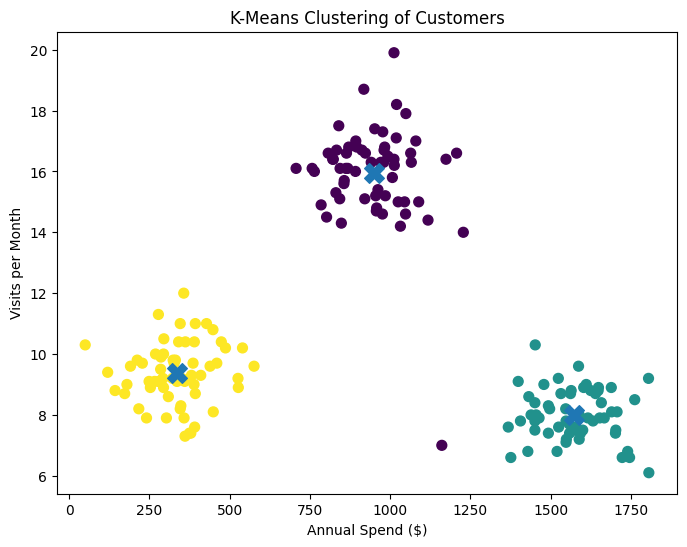

In [ ]:
# Select the two features for clustering
X = customers[["annual_spend", "visits_per_month"]]

# Create K-Means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and predict cluster for each customer
customers["cluster"] = kmeans.fit_predict(X)

# Print first 10 customers with their cluster
print(customers.head(10))

# Get the cluster centers
centers = kmeans.cluster_centers_

print("\nCluster Centers:")
print(centers)

# Plot the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    customers["annual_spend"],
    customers["visits_per_month"],
    c=customers["cluster"],
    s=50
)

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=200
)

plt.title("K-Means Clustering of Customers")
plt.xlabel("Annual Spend ($)")
plt.ylabel("Visits per Month")
plt.show()


Hierarchical Clustering Results:
   annual_spend  visits_per_month  cluster  hierarchical_cluster
0        1432.0               8.6        1                     1
1         977.0              17.3        0                     0
2         831.0              15.3        0                     0
3        1451.0               8.4        1                     1
4         823.0              16.4        0                     0
5        1520.0               6.8        1                     1
6         375.0               7.4        2                     2
7         862.0              16.1        0                     0
8        1648.0               8.8        1                     1
9        1584.0               7.5        1                     1


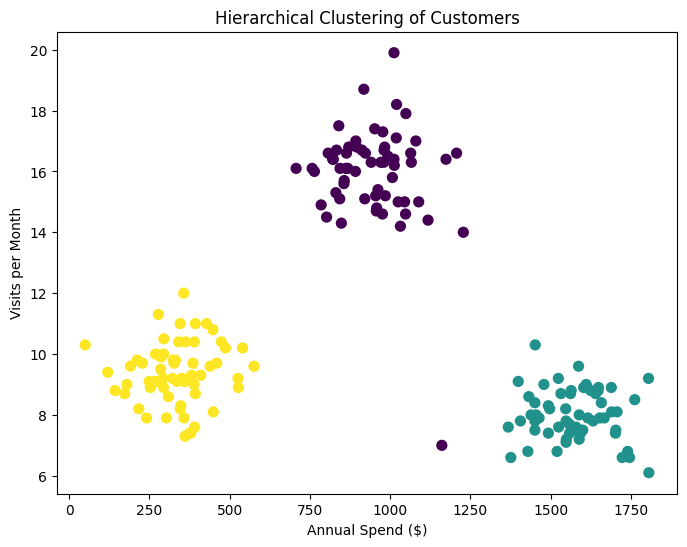

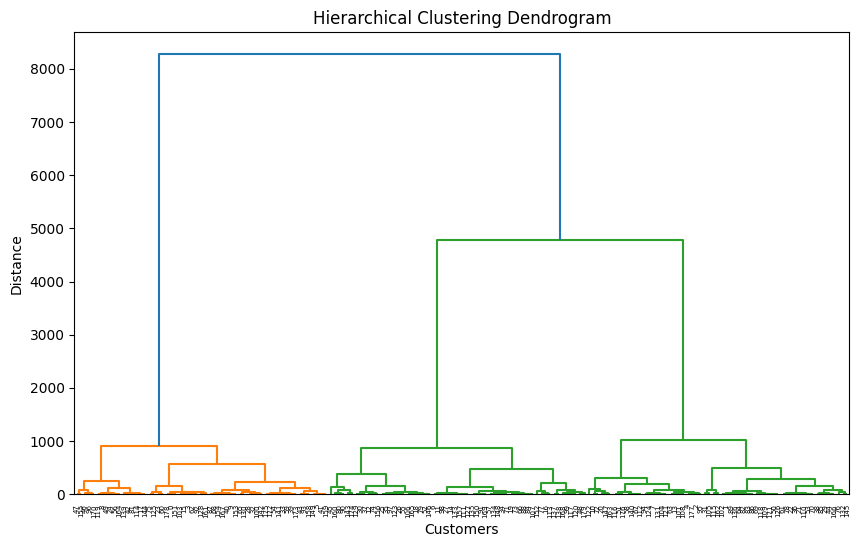

In [ ]:
# ---------------- HIERARCHICAL CLUSTERING ----------------

# Select the same features
X = customers[["annual_spend", "visits_per_month"]]

# Create Hierarchical Clustering model
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Predict clusters
customers["hierarchical_cluster"] = hc.fit_predict(X)

# Display first 10 rows
print("\nHierarchical Clustering Results:")
print(customers.head(10))


# ---------------- PLOT CLUSTERS ----------------

plt.figure(figsize=(8, 6))

plt.scatter(
    customers["annual_spend"],
    customers["visits_per_month"],
    c=customers["hierarchical_cluster"],
    s=50
)

plt.title("Hierarchical Clustering of Customers")
plt.xlabel("Annual Spend ($)")
plt.ylabel("Visits per Month")
plt.show()


# ---------------- DENDROGRAM ----------------

# Create linkage matrix
linkage_matrix = linkage(X, method="ward")

plt.figure(figsize=(10, 6))

dendrogram(linkage_matrix)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")

plt.show()